In [64]:
import numpy as np
import pandas as pd

In [65]:
x1 = np.random.uniform(0,1,20000)
x2 = np.random.uniform(0,1,20000)
x3 = np.random.uniform(0,1,20000)
x4 = np.random.uniform(0,1,20000)
x5 = np.random.uniform(0,1,20000)
x6 = np.random.uniform(0,1,20000)
x7 = np.random.uniform(0,1,20000)
x8 = np.random.uniform(0,1,20000)
x9 = np.random.uniform(0,1,20000)
x10= np.random.uniform(0,1,20000)

### Create Drifts
All drifts are sudden/abrupt.

1. Drift @ [5000:7500]: x1, x3 and x5 are now np.random.uniform(-1,2,2500)
2. Drift @ [10000:12500]: y changes from y_org to y_1) --> Remove label shift 
3. Drift @ [15000:17500]: Drift 1 and 2 appear together

vgl. Vasiloudis (2019)

In [66]:
# Validation drift
x1[2000:3000]=np.random.uniform(-1,2,1000)
x3[2000:3000]=np.random.uniform(-1,2,1000)
x5[2000:3000]=np.random.uniform(-1,2,1000)

# 1. Drift
x1[5000:7500]=np.random.uniform(-1,2,2500)
x3[5000:7500]=np.random.uniform(-1,2,2500)
x5[5000:7500]=np.random.uniform(-1,2,2500)

# 2. Drift
x7[10000:12000]=np.random.uniform(-1,2,2000)
x9[10000:12000]=np.random.uniform(-1,2,2000)
x10[10000:12000]=np.random.uniform(-1,2,2000)

# 3. Drift
x1[16000:20000]=np.random.uniform(-1,2,4000)
x3[16000:20000]=np.random.uniform(-1,2,4000)
x5[16000:20000]=np.random.uniform(-1,2,4000)

y_org = 10*np.sin(np.pi*x1*x2)+20*(x3-0.5)**2 + 10*x4 + 5*x5 + np.random.normal(0,1)
y_1 = 10*np.sin(np.pi*x4*x5)+20*(x2-0.5)**2 + 10*x1 + 5*x3 + np.random.normal(0,1)

In [67]:
relevant_drift_points = [2000, 3000, 5000, 7500, 16000]
irrelevant_drift_points = [10000, 12000]

In [68]:
data = pd.DataFrame([x1,x2,x3,x4,x5,x6,x7,x8,x9,x10, y_org, y_1]).transpose()
data.columns = ['x1','x2','x3','x4','x5','x6','x7','x8','x9','x10', 'y_org', 'y_1']

In [69]:
#data['y_global_abrupt3'] = data['y_org']
#data['y_global_abrupt3'][10000:12500] = data['y_1'][10000:12500]
#data['y_global_abrupt3'][15000:17500] = data['y_1'][15000:17500]

In [70]:
# data = data.drop(['y_org'], axis = 1)

In [71]:
data

,x1,x2,x3,x4,x5,x6,x7,x8,x9,x10,y_org,y_1
0,0.761799,0.108981,0.141544,0.767153,0.058694,0.922132,0.476130,0.636256,0.979777,0.809417,13.673796,12.933919
1,0.594722,0.327617,0.482336,0.937927,0.548911,0.207480,0.142532,0.268401,0.192920,0.311300,18.436267,19.082784
2,0.439565,0.171883,0.553804,0.144112,0.916833,0.132142,0.936658,0.875351,0.817425,0.977633,8.994781,13.491010
3,0.634017,0.386072,0.766801,0.212915,0.621934,0.856674,0.977158,0.599338,0.737204,0.072766,14.176784,14.615306
4,0.808647,0.625483,0.000296,0.656072,0.011585,0.670985,0.933240,0.636073,0.784029,0.513565,22.171306,8.782049
...,...,...,...,...,...,...,...,...,...,...,...,...
19995,-0.829293,0.981020,1.610159,0.255920,0.844713,0.166386,0.228127,0.161590,0.281559,0.437179,26.463915,10.807194
19996,1.595483,0.745647,0.943792,0.006692,1.295571,0.091948,0.933796,0.537054,0.136032,0.858680,5.431857,22.293378
19997,1.687180,0.961368,0.540784,0.554492,-0.343500,0.300092,0.807421,0.834362,0.217103,0.799070,-4.853518,18.340369
19998,0.459929,0.715096,-0.737944,0.567495,1.913617,0.007627,0.567168,0.375710,0.244554,0.489991,55.043048,-0.692730


In [72]:
data.to_csv('friedman_with_2_abrupt_drift.csv', index=False)

In [73]:
import matplotlib.pyplot as plt

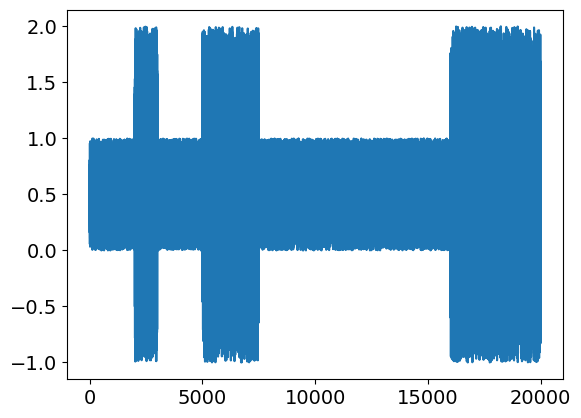

In [74]:
plt.plot(data['x1'])

In [75]:
#plt.plot(data['y_global_abrupt3'])

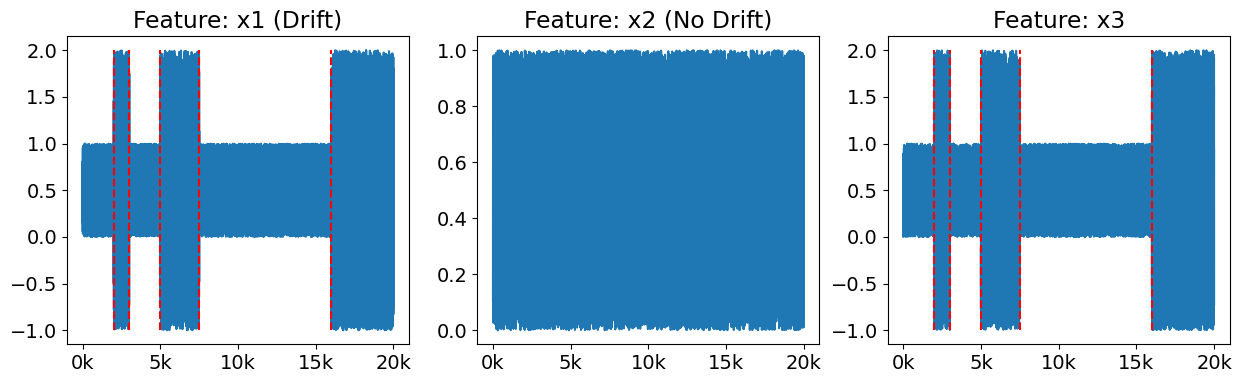

In [76]:
import matplotlib.ticker as ticker

#Plot features
font = {'size'   : 14}

plt.rc('font', **font)
fig, ax = plt.subplots(1, 3, figsize=(15,4))


ax[0].plot(data['x1'])
ax[0].set_title('Feature: x1 (Drift)')
ax[0].xaxis.set_major_formatter(ticker.FuncFormatter(lambda x, pos: '{}'.format(int(x/1000)) + 'k'))
ax[0].vlines(2000, -1, 2, colors='r', linestyles='dashed')
ax[0].vlines(3000, -1, 2, colors='r', linestyles='dashed')
ax[0].vlines(5000, -1, 2, colors='r', linestyles='dashed')
ax[0].vlines(7500, -1, 2, colors='r', linestyles='dashed')
ax[0].vlines(16000, -1, 2, colors='r', linestyles='dashed')

ax[1].plot(data['x2'])
ax[1].set_title('Feature: x2 (No Drift)')
ax[1].xaxis.set_major_formatter(ticker.FuncFormatter(lambda x, pos: '{}'.format(int(x/1000)) + 'k'))

ax[2].plot(data['x3'])
ax[2].set_title('Feature: x3')
ax[2].xaxis.set_major_formatter(ticker.FuncFormatter(lambda x, pos: '{}'.format(int(x/1000)) + 'k'))
ax[2].vlines(2000, -1, 2, colors='r', linestyles='dashed')
ax[2].vlines(3000, -1, 2, colors='r', linestyles='dashed')
ax[2].vlines(5000, -1, 2, colors='r', linestyles='dashed')
ax[2].vlines(7500, -1, 2, colors='r', linestyles='dashed')
ax[2].vlines(16000, -1, 2, colors='r', linestyles='dashed')
# ax[2].plot(data['y_global_abrupt3'])
# ax[2].set_title('Target')
# ax[2].xaxis.set_major_formatter(ticker.FuncFormatter(lambda x, pos: '{}'.format(int(x/1000)) + 'k'))

# plt.savefig('friedman_abrupt.png', bbox_inches='tight', dpi=300)


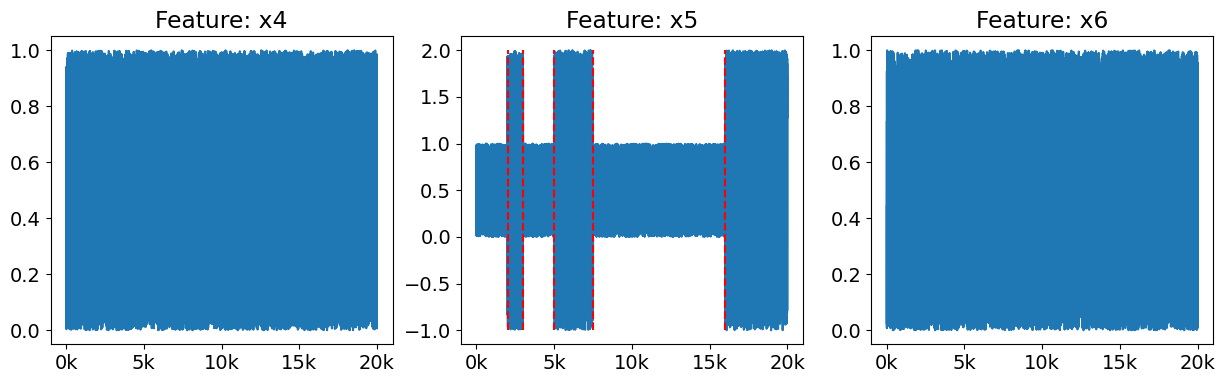

In [77]:
#Plot features
font = {'size'   : 14}

plt.rc('font', **font)
fig, ax = plt.subplots(1, 3, figsize=(15,4))


ax[0].plot(data['x4'])
ax[0].set_title('Feature: x4')
ax[0].xaxis.set_major_formatter(ticker.FuncFormatter(lambda x, pos: '{}'.format(int(x/1000)) + 'k'))

ax[1].plot(data['x5'])
ax[1].set_title('Feature: x5')
ax[1].xaxis.set_major_formatter(ticker.FuncFormatter(lambda x, pos: '{}'.format(int(x/1000)) + 'k'))
ax[1].vlines(2000, -1, 2, colors='r', linestyles='dashed')
ax[1].vlines(3000, -1, 2, colors='r', linestyles='dashed')
ax[1].vlines(5000, -1, 2, colors='r', linestyles='dashed')
ax[1].vlines(7500, -1, 2, colors='r', linestyles='dashed')
ax[1].vlines(16000, -1, 2, colors='r', linestyles='dashed')

ax[2].plot(data['x6'])
ax[2].set_title('Feature: x6')
ax[2].xaxis.set_major_formatter(ticker.FuncFormatter(lambda x, pos: '{}'.format(int(x/1000)) + 'k'))

# ax[2].plot(data['y_global_abrupt3'])
# ax[2].set_title('Target')
# ax[2].xaxis.set_major_formatter(ticker.FuncFormatter(lambda x, pos: '{}'.format(int(x/1000)) + 'k'))

# plt.savefig('friedman_abrupt.png', bbox_inches='tight', dpi=300)


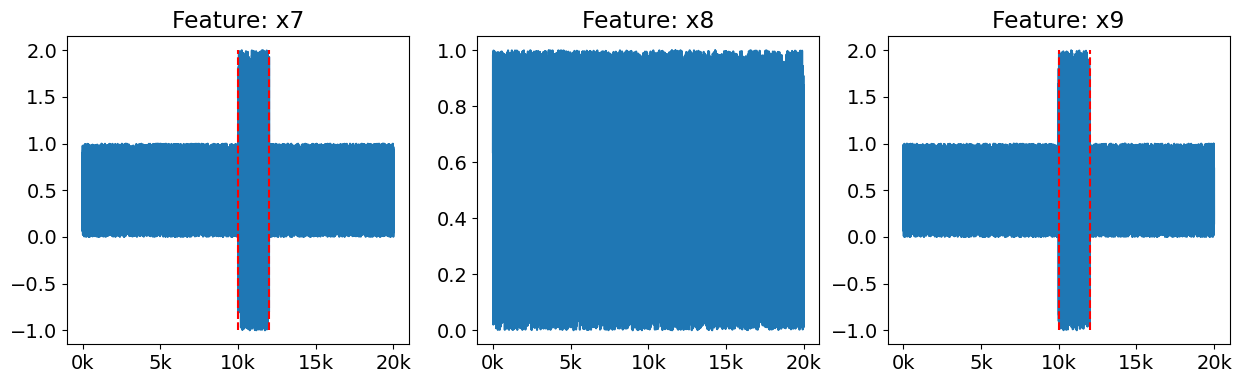

In [78]:
#Plot features
font = {'size'   : 14}

plt.rc('font', **font)
fig, ax = plt.subplots(1, 3, figsize=(15,4))


ax[0].plot(data['x7'])
ax[0].set_title('Feature: x7')
ax[0].xaxis.set_major_formatter(ticker.FuncFormatter(lambda x, pos: '{}'.format(int(x/1000)) + 'k'))
ax[0].vlines(10000, -1, 2, colors='r', linestyles='dashed')
ax[0].vlines(12000, -1, 2, colors='r', linestyles='dashed')

ax[1].plot(data['x8'])
ax[1].set_title('Feature: x8')
ax[1].xaxis.set_major_formatter(ticker.FuncFormatter(lambda x, pos: '{}'.format(int(x/1000)) + 'k'))

ax[2].plot(data['x9'])
ax[2].set_title('Feature: x9')
ax[2].xaxis.set_major_formatter(ticker.FuncFormatter(lambda x, pos: '{}'.format(int(x/1000)) + 'k'))
ax[2].vlines(10000, -1, 2, colors='r', linestyles='dashed')
ax[2].vlines(12000, -1, 2, colors='r', linestyles='dashed')
# ax[2].plot(data['y_global_abrupt3'])
# ax[2].set_title('Target')
# ax[2].xaxis.set_major_formatter(ticker.FuncFormatter(lambda x, pos: '{}'.format(int(x/1000)) + 'k'))

# plt.savefig('friedman_abrupt.png', bbox_inches='tight', dpi=300)


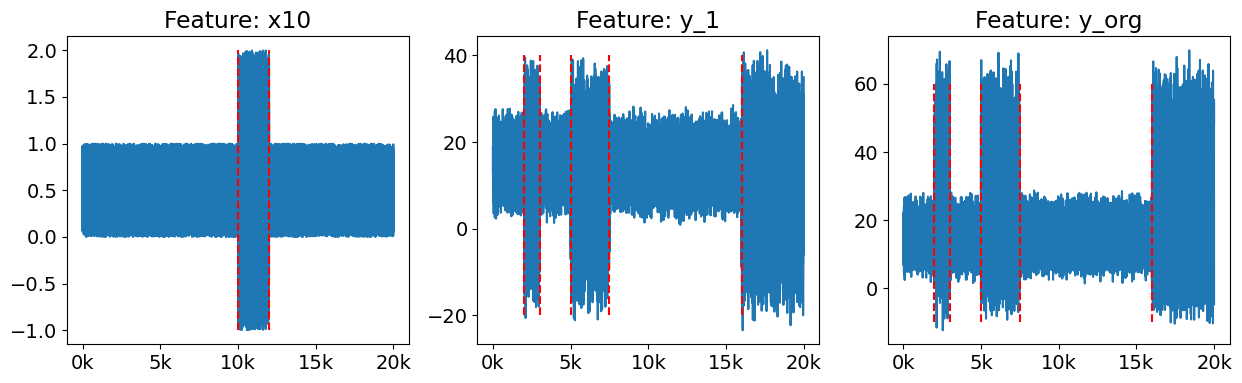

In [79]:
#Plot features
font = {'size'   : 14}

plt.rc('font', **font)
fig, ax = plt.subplots(1, 3, figsize=(15,4))


ax[0].plot(data['x10'])
ax[0].set_title('Feature: x10')
ax[0].xaxis.set_major_formatter(ticker.FuncFormatter(lambda x, pos: '{}'.format(int(x/1000)) + 'k'))
ax[0].vlines(10000, -1, 2, colors='r', linestyles='dashed')
ax[0].vlines(12000, -1, 2, colors='r', linestyles='dashed')

ax[1].plot(data['y_1'])
ax[1].set_title('Feature: y_1')
ax[1].xaxis.set_major_formatter(ticker.FuncFormatter(lambda x, pos: '{}'.format(int(x/1000)) + 'k'))
ax[1].vlines(2000, -20, 40, colors='r', linestyles='dashed')
ax[1].vlines(3000, -20, 40, colors='r', linestyles='dashed')
ax[1].vlines(5000, -20, 40, colors='r', linestyles='dashed')
ax[1].vlines(7500, -20, 40, colors='r', linestyles='dashed')
ax[1].vlines(16000, -20, 40, colors='r', linestyles='dashed')

ax[2].plot(data['y_org'])
ax[2].set_title('Feature: y_org')
ax[2].xaxis.set_major_formatter(ticker.FuncFormatter(lambda x, pos: '{}'.format(int(x/1000)) + 'k'))
ax[2].vlines(2000, -10, 60, colors='r', linestyles='dashed')
ax[2].vlines(3000, -10, 60, colors='r', linestyles='dashed')
ax[2].vlines(5000, -10, 60, colors='r', linestyles='dashed')
ax[2].vlines(7500, -10, 60, colors='r', linestyles='dashed')
ax[2].vlines(16000, -10, 60, colors='r', linestyles='dashed')
# ax[2].plot(data['y_global_abrupt3'])
# ax[2].set_title('Target')
# ax[2].xaxis.set_major_formatter(ticker.FuncFormatter(lambda x, pos: '{}'.format(int(x/1000)) + 'k'))

# plt.savefig('friedman_abrupt.png', bbox_inches='tight', dpi=300)
